

2.  종속변수 불균형 처리

3. 수치형 변수 스케일링 > 파이프라인

4. 범주형 변수 인코딩 > 파이프라인

5. Train/Valid/Test 데이터 분할 (7 : 1.5 : 1.5)

6. 다중공선성, 변수 간에 상관성 확인

7. 변수 선택
    - 제거할 변수
    - 파생변수

> 평가기준 : recall과 f1, confusion matrix을 중심지표로 설정 (recall : 실제 지진피해가 큰데, 피해가 크지 않다고 예측)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

raw_df = pd.read_csv("nepal_building_damage.csv")
df = raw_df.copy()

df = df.drop(columns=["building_id"])  # 제거할 컬럼(건물 id)

In [ ]:
# 카이제곱
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# 지역 컬럼
geo_cols = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]

# 범주형 변수 선택 (문자형 + 0/1 변수)
cat_cols = df.select_dtypes(include="object").columns.tolist()
cat_cols += [col for col in df.columns if col.startswith("has_")]

results = []

for geo in geo_cols:
    for col in cat_cols:
        table = pd.crosstab(df[geo], df[col])

        chi2, p, dof, expected = chi2_contingency(table)  # 카이제곱

        # 연관성 강도 (Cramér's V)
        v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

        results.append(
            {
                "지역": geo,
                "변수": col,
                "Chi2": chi2,
                "p-value": p,
                "Cramers_V": v,
                "기대빈도5미만(%)": (expected < 5).mean() * 100,
            }
        )

result_df = pd.DataFrame(results)

# 지역별 결과 출력
for geo in geo_cols:
    print(f"\n===== {geo} =====")
    print(
        result_df[result_df["지역"] == geo]
        .sort_values("Cramers_V", ascending=False)
        .to_string(index=False)
    )

C:\Users\wls03\AppData\Local\Temp\ipykernel_32672\1480855800.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()



===== geo_level_1_id =====
            지역                                     변수         Chi2       p-value  Cramers_V  기대빈도5미만(%)
geo_level_1_id    has_superstructure_mud_mortar_stone 70562.384397  0.000000e+00   0.520354    0.000000
geo_level_1_id    has_superstructure_mud_mortar_brick 65948.682758  0.000000e+00   0.503054    0.000000
geo_level_1_id           has_superstructure_adobe_mud 60974.321332  0.000000e+00   0.483710    0.000000
geo_level_1_id              has_superstructure_bamboo 37458.634993  0.000000e+00   0.379130    0.000000
geo_level_1_id has_superstructure_cement_mortar_brick 27672.616360  0.000000e+00   0.325865    0.000000
geo_level_1_id              has_superstructure_timber 25602.525871  0.000000e+00   0.313439    0.000000
geo_level_1_id                        foundation_type 99719.241324  0.000000e+00   0.309294    1.935484
geo_level_1_id                              roof_type 35989.146199  0.000000e+00   0.262774    0.000000
geo_level_1_id                      

In [ ]:
geo_cols = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]

# 범주형 변수 전체 선택
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
cat_cols += [c for c in df.columns if c.startswith("has_")]
cat_cols = list(set(cat_cols) - set(geo_cols) - {"damage_grade"})

for geo in geo_cols:
    for col in cat_cols:

        # 카이제곱 검정
        table = pd.crosstab(df[geo], df[col])
        if min(table.shape) < 2:
            continue

        p = chi2_contingency(table)[1]

        if p < 0.05:

            # 0/1 변수 → 지역별 사용률
            if set(df[col].dropna().unique()) <= {0, 1}:
                df[f"{geo}_{col}_rate"] = df.groupby(geo)[col].transform("mean")

            # 일반 범주형 변수 → 지역별 해당 유형 비율
            else:
                df[f"{geo}_{col}_freq"] = df.groupby([geo, col])[col].transform(
                    "size"
                ) / df.groupby(geo)[col].transform("size")

# 2차적 사용용도 x 2등급 피해
for col in df.columns:
    if col.startswith("has_secondary_use_"):
        new_col = f"{col.replace('has_', '')}_grade2"
        df[new_col] = ((df[col] == 1) & (df["damage_grade"] == 2)).astype(int)

# 2차적 사용용도 x 3등급 피해
for col in df.columns:
    if col.startswith("has_secondary_use_"):
        new_col = f"{col.replace('has_', '')}_grade3"
        df[new_col] = ((df[col] == 1) & (df["damage_grade"] == 3)).astype(int)


# 면적 / 높이
df["area_height"] = df["area_percentage"] / df["height_percentage"]

C:\Users\wls03\AppData\Local\Temp\ipykernel_36796\1997384314.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
C:\Users\wls03\AppData\Local\Temp\ipykernel_36796\1997384314.py:49: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['area_height'] = df['area_percentage'] 

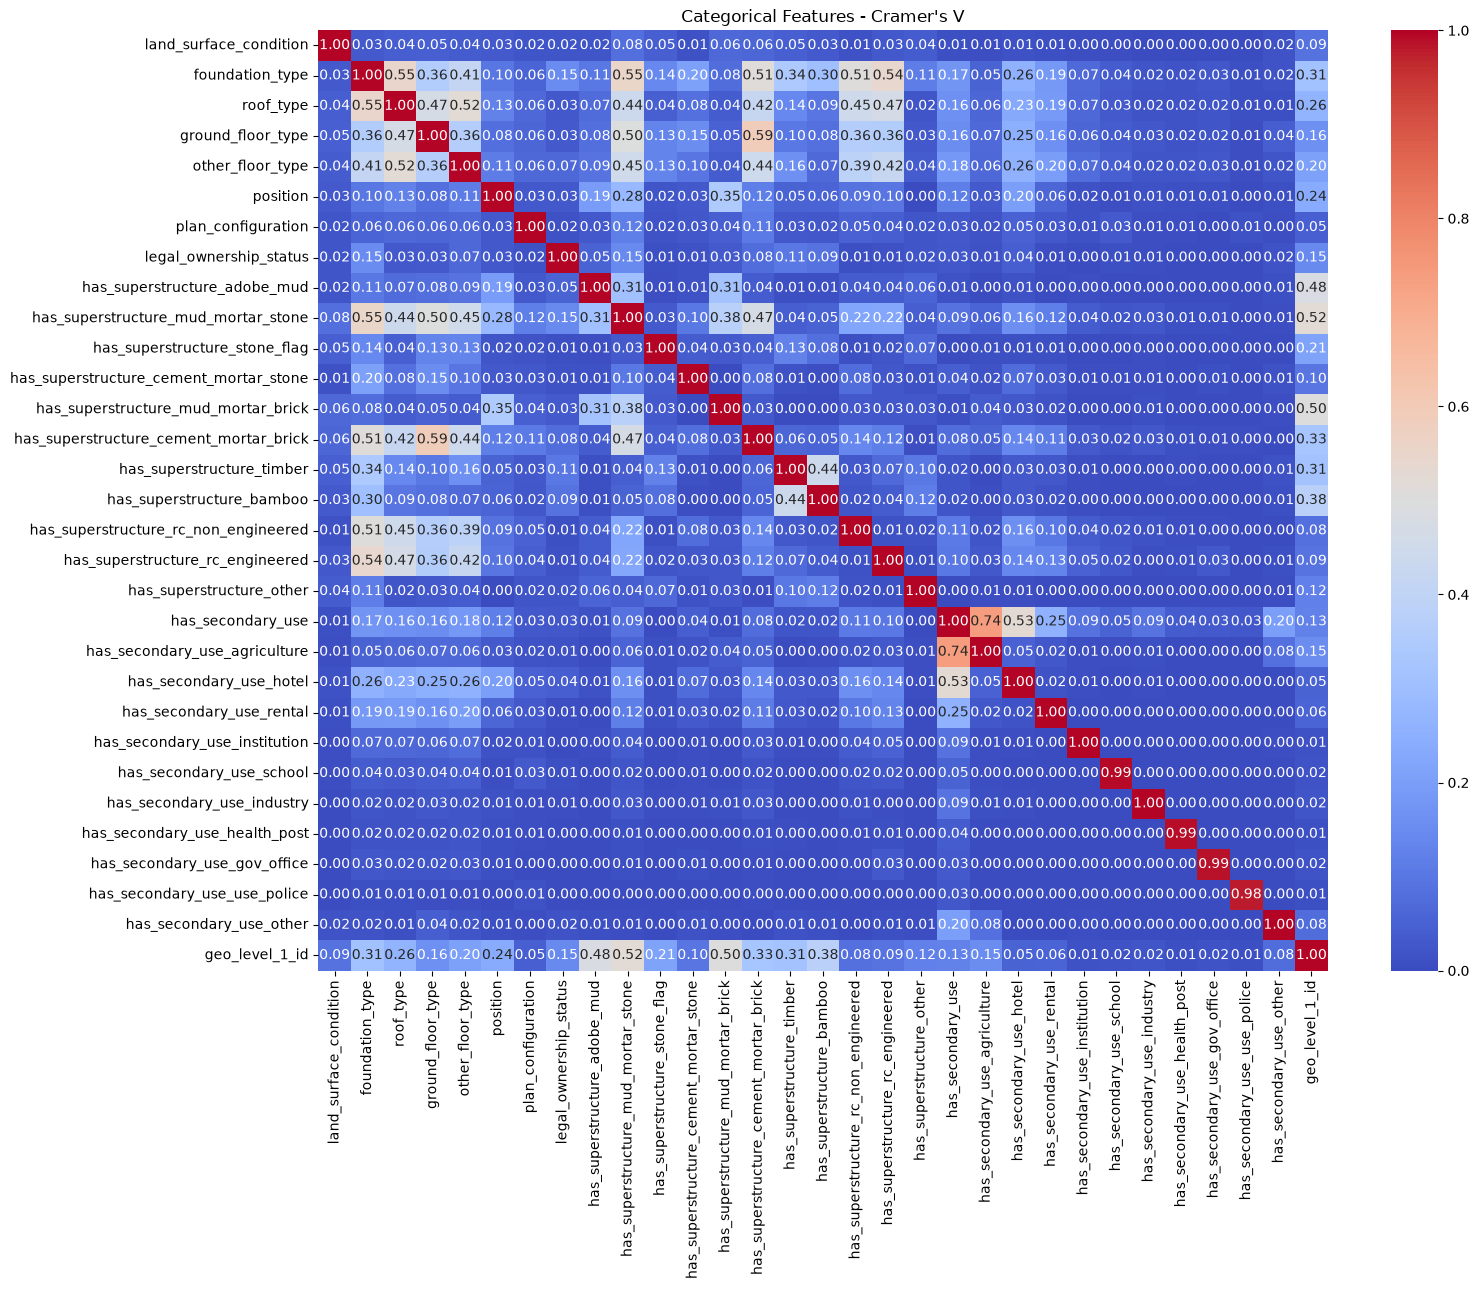

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# 원본 데이터
df = pd.read_csv("nepal_building_damage.csv")

# 범주형 변수 선택
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

# 0/1 범주형 변수 추가
cat_cols += [col for col in df.columns if col.startswith("has_")]

# 지역 변수 추가 (대지역만)
cat_cols += ["geo_level_1_id"]

# 중복 제거
cat_cols = list(dict.fromkeys(cat_cols))

# 종속변수 제외
cat_cols = [col for col in cat_cols if col != "damage_grade"]


# Cramér's V 계산 함수
def cramers_v(x, y):

    table = pd.crosstab(x, y)

    if min(table.shape) < 2:
        return 0

    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()

    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


# 범주형 변수 간 연관성 계산
corr = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

for col1 in cat_cols:
    for col2 in cat_cols:
        corr.loc[col1, col2] = cramers_v(df[col1], df[col2])


# 히트맵 시각화
plt.figure(figsize=(16, 13))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1)

plt.title("Categorical Features - Cramer's V")
plt.tight_layout()
plt.show()

### 피처 엔지니어링

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2_contingency

raw_df = pd.read_csv("nepal_building_damage.csv")
df = raw_df.copy()

df = df.drop(columns=["building_id"])  # 제거할 컬럼(건물 id)

In [ ]:
# 1) 2차적 사용용도 x 2등급 피해
for col in df.columns:
    if col.startswith("has_secondary_use_"):
        new_col = f"{col.replace('has_', '')}_grade2"
        df[new_col] = ((df[col] == 1) & (df["damage_grade"] == 2)).astype(int)


# 2) 2차적 사용용도 x 3등급 피해
for col in df.columns:
    if col.startswith("has_secondary_use_"):
        new_col = f"{col.replace('has_', '')}_grade3"
        df[new_col] = ((df[col] == 1) & (df["damage_grade"] == 3)).astype(int)


# 3) 면적 대비 높이의 비율
df["height_area_ratio"] = df["height_percentage"] / df["area_percentage"].clip(lower=1)


# 4) 사용한 재료(meterior)의 수 파생변수 생성
material_cols = [col for col in df.columns if col.startswith("has_superstructure_")]  # 건물에 사용한 재료 컬럼

df["material_count"] = df[material_cols].sum(axis=1)


# 5) 부가적으로 사용한 용도의 수 파생변수 생성 (부가적으로 사용한 용도 컬럼)
secondary_use_cols = [ col for col in df.columns if col.startswith("has_secondary_use_")]  # 부가적으로 사용한 용도 컬럼

df["secondary_use_count"] = df[secondary_use_cols].sum(axis=1)


# 6) 층당 상대 높이
df["height_per_floor"] = df["height_percentage"] / df["count_floors_pre_eq"].clip(lower=1)


# 7) 건축재료를 그룹별로 나누는 파생변수 (건축재료 컬럼) > 모델링 후 수정점 : 모르타르는 대중적인 건축재료이므로, 모르타르를 포함한 건축재료 그룹을 나누는 것이 좋다고 판단됨.
# 7-1) concrete_count
concrete_cols = [
    "has_superstructure_cement_mortar_stone",
    "has_superstructure_cement_mortar_brick",
    "has_superstructure_rc_non_engineered",
    "has_superstructure_rc_engineered",
]

df["concrete_count"] = df[concrete_cols].sum(axis=1)

# 7-2) mud_count
mud_cols = [
    "has_superstructure_adobe_mud",
    "has_superstructure_mud_mortar_stone",
    "has_superstructure_mud_mortar_brick",
]

df["mud_count"] = df[mud_cols].sum(axis=1)


# 8) 건물의 기초, 지붕, 바닥 구조, 지표면 상태를 조합한 파생변수 생성
df["foundation_roof"] = (
    df["foundation_type"] + "_" + df["roof_type"]
)  # 기초유형 + 지붕유형

df["ground_other_floor"] = (
    df["ground_floor_type"] + "_" + df["other_floor_type"]
)  # 바닥유형 + 상부층 구조 유형

df["foundation_ground"] = (
    df["foundation_type"] + "_" + df["ground_floor_type"]
)  # 기초유형 + 지상 최하층 바닥 유형

df["surface_condition"] = (
    df["land_surface_condition"] + "_" + df["ground_floor_type"]
)  # 지표면 상태 + 지상 최하층 바닥 유형


# 9) 지역별 카이제곱 검정을 통한 유의변수 - 범주형 변수의 사용률/비율 파생변수 생성
geo_cols = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]

# 범주형 변수 전체 선택
cat_cols = df.select_dtypes(include=["object", "str", "category"]).columns.tolist()
cat_cols += [c for c in df.columns if c.startswith("has_")]
cat_cols = list(set(cat_cols) - set(geo_cols) - {"damage_grade"})

for geo in geo_cols:
    for col in cat_cols:

        # 카이제곱 검정
        table = pd.crosstab(df[geo], df[col])
        if min(table.shape) < 2:
            continue

        p = chi2_contingency(table)[1]

        if p < 0.05:

            # 0/1 변수 → 지역별 사용률
            if set(df[col].dropna().unique()) <= {0, 1}:
                df[f"{geo}_{col}_rate"] = df.groupby(geo)[col].transform("mean")

            # 일반 범주형 변수 → 지역별 해당 유형 비율
            else:
                df[f"{geo}_{col}_freq"] = df.groupby([geo, col])[col].transform(
                    "size"
                ) / df.groupby(geo)[col].transform("size")

# 10) geo_level_1_id, geo_level_2_id, geo_level_3_id 컬럼을 통한 지역별 건물의 평균 연식(age) 파생변수 생성
for geo in geo_cols:
    df[f"{geo}_age_mean"] = df.groupby(geo)["age"].transform("mean")


df.head()

# df  => 파생변수 데이터 변수

C:\Users\wls03\AppData\Local\Temp\ipykernel_18548\2277143423.py:94: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{geo}_{col}_rate"] = df.groupby(geo)[col].transform("mean")
C:\Users\wls03\AppData\Local\Temp\ipykernel_18548\2277143423.py:98: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{geo}_{col}_freq"] = df.groupby([geo, col])[col].transform("size") / df.groupby(geo)[col].transform("size")
C:\Users\wls03\AppData\Local\Temp\ipykernel_18548\2277143423.py:94: PerformanceWarning: DataFrame is highly fragmented.  This is

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,...,geo_level_3_id_has_superstructure_cement_mortar_stone_rate,geo_level_3_id_has_secondary_use_health_post_rate,geo_level_3_id_roof_type_freq,geo_level_3_id_plan_configuration_freq,geo_level_3_id_foundation_roof_freq,geo_level_3_id_surface_condition_freq,geo_level_3_id_other_floor_type_freq,geo_level_1_id_age_mean,geo_level_2_id_age_mean,geo_level_3_id_age_mean
0,30,266,1224,1,25,5,2,t,r,n,...,0.0,0.0,0.971429,1.00000,0.971429,0.942857,0.228571,30.152643,25.183246,28.428571
1,17,409,12182,2,0,13,7,t,r,n,...,0.0,0.0,1.000000,1.00000,1.000000,0.692308,0.846154,22.871682,20.751880,16.538462
2,17,716,7056,2,5,12,6,o,r,q,...,0.0,0.0,1.000000,0.81250,1.000000,0.812500,0.937500,22.871682,17.487310,10.000000
3,4,651,105,2,80,5,4,n,r,n,...,0.0,0.0,0.875000,1.00000,0.875000,0.843750,0.312500,21.037548,25.019305,20.625000
4,3,1387,3909,5,40,5,10,t,r,n,...,0.0,0.0,0.876106,0.99115,0.876106,0.893805,0.371681,38.383952,60.549020,60.221239


## 모델링

## 로지스틱 모델링

c:\Users\wls03\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


===== Logistic Regression 검증 성능 =====
Accuracy : 0.7100537221795856
Precision: 0.6570229735162783
Recall   : 0.7408802896507721
F1-score : 0.6825655276728736

               precision    recall  f1-score   support

           0       0.48      0.81      0.60      3768
           1       0.80      0.68      0.74     22239
           2       0.69      0.73      0.71     13083

    accuracy                           0.71     39090
   macro avg       0.66      0.74      0.68     39090
weighted avg       0.73      0.71      0.71     39090



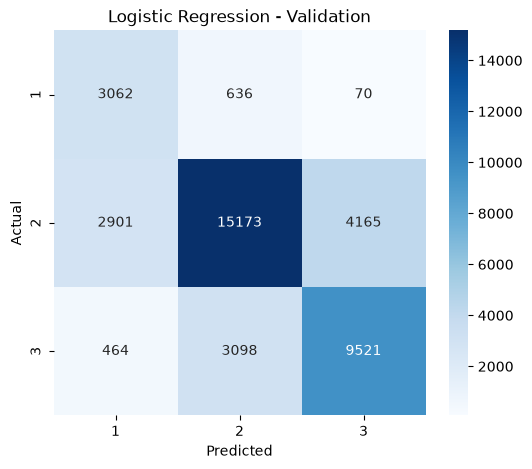

===== 테스트 성능 =====
Accuracy : 0.7112890435138522
Precision: 0.6576912309238527
Recall   : 0.7416370283490076
F1-score : 0.6830716195076137


In [ ]:
# ===================================================
# 1. 라이브러리
# ===================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC

# ===================================================
# 2. 데이터 불러오기
# ===================================================
df_vars = df.copy()

X = df_vars.drop(columns="damage_grade")
y = df_vars["damage_grade"] - 1  # 1,2,3 → 0,1,2


# ===================================================
# 3. 데이터 분할 (7 : 1.5 : 1.5)
# ===================================================
X_tr, X_temp, y_tr, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)


# ===================================================
# 4. 범주형 / 연속형 변수 구분
# ===================================================
geo_cols = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
cat_cols += [c for c in X.columns if c.startswith("has_")]
cat_cols += geo_cols

# 0/1로 생성한 파생변수도 범주형
cat_cols += [c for c in X.columns if c.endswith(("_grade2", "_grade3"))]

cat_cols = list(dict.fromkeys(cat_cols))
num_cols = [c for c in X.columns if c not in cat_cols]


# ===================================================
# 5. 인코딩 / 스케일링
# ===================================================
# SMOTENC 이전 전처리
preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), num_cols),
        (
            "cat",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            cat_cols,
        ),
    ]
)

# 범주형 컬럼 위치
cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))

# SMOTENC 이후 원핫인코딩
onehot = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), cat_idx)],
    remainder="passthrough",
    sparse_threshold=1.0,
)


# ===================================================
# 6. SMOTENC + Logistic Regression
# ===================================================
pipe = Pipeline(
    [
        ("preprocess", preprocessor),
        ("smote", SMOTENC(categorical_features=cat_idx, random_state=42)),
        ("onehot", onehot),
        ("model", LogisticRegression(random_state=42)),
    ]
)


# ===================================================
# 7. 모델 학습
# ===================================================
pipe.fit(X_tr, y_tr)


# ===================================================
# 8. 검증 데이터 평가
# ===================================================
y_pred = pipe.predict(X_val)

print("===== Logistic Regression 검증 성능 =====")
print("Accuracy :", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, average="macro", zero_division=0))
print("Recall   :", recall_score(y_val, y_pred, average="macro"))
print("F1-score :", f1_score(y_val, y_pred, average="macro"))

print("\n", classification_report(y_val, y_pred))


# ===================================================
# 9. 검증 혼동행렬
# ===================================================
cm = confusion_matrix(y_val, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", xticklabels=[1, 2, 3], yticklabels=[1, 2, 3]
)

plt.title("Logistic Regression - Validation")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# ===================================================
# 10. 테스트 데이터 최종 평가
# ===================================================
y_test_pred = pipe.predict(X_test)

print("===== 테스트 성능 =====")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print(
    "Precision:", precision_score(y_test, y_test_pred, average="macro", zero_division=0)
)
print("Recall   :", recall_score(y_test, y_test_pred, average="macro"))
print("F1-score :", f1_score(y_test, y_test_pred, average="macro"))

## XGB 모델링

===== Logistic Regression 검증 성능 =====
Accuracy : 0.7525965720133027
Precision: 0.7253647202028423
Recall   : 0.7115956223332844
F1-score : 0.7179045933507555

               precision    recall  f1-score   support

           0       0.66      0.64      0.65      3768
           1       0.77      0.81      0.79     22239
           2       0.74      0.69      0.71     13083

    accuracy                           0.75     39090
   macro avg       0.73      0.71      0.72     39090
weighted avg       0.75      0.75      0.75     39090



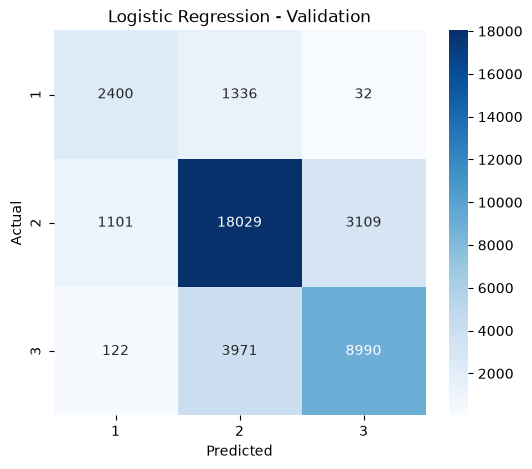

===== 테스트 성능 =====
Accuracy : 0.7543424317617866
Precision: 0.7279445601435387
Recall   : 0.7119332250045979
F1-score : 0.7193352300334794


In [ ]:
# ===================================================
# 1. 라이브러리
# ===================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC

# ===================================================
# 2. 데이터 불러오기
# ===================================================
df_vars = pd.read_csv("nepal_building_damage_with_features.csv")

X = df_vars.drop(columns="damage_grade")
y = df_vars["damage_grade"] - 1  # 1,2,3 → 0,1,2


# ===================================================
# 3. 데이터 분할 (7 : 1.5 : 1.5)
# ===================================================
X_tr, X_temp, y_tr, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)


# ===================================================
# 4. 범주형 / 연속형 변수 구분
# ===================================================
geo_cols = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
cat_cols += [c for c in X.columns if c.startswith("has_")]
cat_cols += geo_cols

# 0/1로 생성한 파생변수도 범주형
cat_cols += [c for c in X.columns if c.endswith(("_grade2", "_grade3"))]

cat_cols = list(dict.fromkeys(cat_cols))
num_cols = [c for c in X.columns if c not in cat_cols]


# ===================================================
# 5. 인코딩 / 스케일링
# ===================================================
# SMOTENC 이전 전처리
preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), num_cols),
        (
            "cat",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            cat_cols,
        ),
    ]
)

# 범주형 컬럼 위치
cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))

# SMOTENC 이후 원핫인코딩
onehot = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), cat_idx)],
    remainder="passthrough",
    sparse_threshold=1.0,
)


# ===================================================
# 6. SMOTENC + Logistic Regression
# ===================================================
pipe = Pipeline(
    [
        ("preprocess", preprocessor),
        ("smote", SMOTENC(categorical_features=cat_idx, random_state=42)),
        ("onehot", onehot),
        ("model", XGBClassifier(random_state=42)),
    ]
)


# ===================================================
# 7. 모델 학습
# ===================================================
pipe.fit(X_tr, y_tr)


# ===================================================
# 8. 검증 데이터 평가
# ===================================================
y_pred = pipe.predict(X_val)

print("===== Logistic Regression 검증 성능 =====")
print("Accuracy :", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, average="macro", zero_division=0))
print("Recall   :", recall_score(y_val, y_pred, average="macro"))
print("F1-score :", f1_score(y_val, y_pred, average="macro"))

print("\n", classification_report(y_val, y_pred))


# ===================================================
# 9. 검증 혼동행렬
# ===================================================
cm = confusion_matrix(y_val, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", xticklabels=[1, 2, 3], yticklabels=[1, 2, 3]
)

plt.title("Logistic Regression - Validation")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# ===================================================
# 10. 테스트 데이터 최종 평가
# ===================================================
y_test_pred = pipe.predict(X_test)

print("===== 테스트 성능 =====")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print(
    "Precision:", precision_score(y_test, y_test_pred, average="macro", zero_division=0)
)
print("Recall   :", recall_score(y_test, y_test_pred, average="macro"))
print("F1-score :", f1_score(y_test, y_test_pred, average="macro"))

## LGBM 모델링

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.163986 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 38056
[LightGBM] [Info] Number of data points in the train set: 311343, number of used features: 6174
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
===== Logistic Regression 검증 성능 =====
Accuracy : 0.7542338193911486
Precision: 0.7278710063351159
Recall   : 0.7120938311734949
F1-score : 0.7190908895431128

               precision    recall  f1-score   support

           0       0.66      0.64      0.65      3768
           1       0.77      0.82      0.79     22239
           2       0.75      0.68      0.71     13083

    accuracy                           0.75     39090
   macro avg       0.73      0.71      0.72     39090
weighted avg       0.75      0.75      0.75     39090



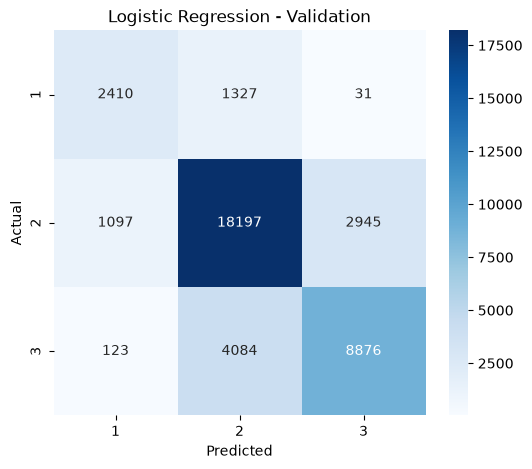

===== 테스트 성능 =====
Accuracy : 0.754368013097644
Precision: 0.7290872786713801
Recall   : 0.7093149155122126
F1-score : 0.7182175887275596


In [ ]:
# ===================================================
# 1. 라이브러리
# ===================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC

# ===================================================
# 2. 데이터 불러오기
# ===================================================
df_vars = pd.read_csv("nepal_building_damage_with_features.csv")

X = df_vars.drop(columns="damage_grade")
y = df_vars["damage_grade"] - 1  # 1,2,3 → 0,1,2


# ===================================================
# 3. 데이터 분할 (7 : 1.5 : 1.5)
# ===================================================
X_tr, X_temp, y_tr, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)


# ===================================================
# 4. 범주형 / 연속형 변수 구분
# ===================================================
geo_cols = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
cat_cols += [c for c in X.columns if c.startswith("has_")]
cat_cols += geo_cols

# 0/1로 생성한 파생변수도 범주형
cat_cols += [c for c in X.columns if c.endswith(("_grade2", "_grade3"))]

cat_cols = list(dict.fromkeys(cat_cols))
num_cols = [c for c in X.columns if c not in cat_cols]


# ===================================================
# 5. 인코딩 / 스케일링
# ===================================================
# SMOTENC 이전 전처리
preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), num_cols),
        (
            "cat",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            cat_cols,
        ),
    ]
)

# 범주형 컬럼 위치
cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))

# SMOTENC 이후 원핫인코딩
onehot = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), cat_idx)],
    remainder="passthrough",
    sparse_threshold=1.0,
)


# ===================================================
# 6. SMOTENC + LGBMClassifier
# ===================================================
pipe = Pipeline(
    [
        ("preprocess", preprocessor),
        ("smote", SMOTENC(categorical_features=cat_idx, random_state=42)),
        ("onehot", onehot),
        ("model", LGBMClassifier(random_state=42)),
    ]
)


# ===================================================
# 7. 모델 학습
# ===================================================
pipe.fit(X_tr, y_tr)


# ===================================================
# 8. 검증 데이터 평가
# ===================================================
y_pred = pipe.predict(X_val)

print("===== Logistic Regression 검증 성능 =====")
print("Accuracy :", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, average="macro", zero_division=0))
print("Recall   :", recall_score(y_val, y_pred, average="macro"))
print("F1-score :", f1_score(y_val, y_pred, average="macro"))

print("\n", classification_report(y_val, y_pred))


# ===================================================
# 9. 검증 혼동행렬
# ===================================================
cm = confusion_matrix(y_val, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", xticklabels=[1, 2, 3], yticklabels=[1, 2, 3]
)

plt.title("Logistic Regression - Validation")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# ===================================================
# 10. 테스트 데이터 최종 평가
# ===================================================
y_test_pred = pipe.predict(X_test)

print("===== 테스트 성능 =====")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print(
    "Precision:", precision_score(y_test, y_test_pred, average="macro", zero_division=0)
)
print("Recall   :", recall_score(y_test, y_test_pred, average="macro"))
print("F1-score :", f1_score(y_test, y_test_pred, average="macro"))

## Cat 모델링

Learning rate set to 0.106042
0:	learn: 1.0334989	total: 219ms	remaining: 3m 39s
1:	learn: 0.9826090	total: 298ms	remaining: 2m 28s
2:	learn: 0.9429596	total: 369ms	remaining: 2m 2s
3:	learn: 0.9106810	total: 449ms	remaining: 1m 51s
4:	learn: 0.8824169	total: 522ms	remaining: 1m 43s
5:	learn: 0.8576629	total: 590ms	remaining: 1m 37s
6:	learn: 0.8365751	total: 664ms	remaining: 1m 34s
7:	learn: 0.8191990	total: 728ms	remaining: 1m 30s
8:	learn: 0.8041452	total: 795ms	remaining: 1m 27s
9:	learn: 0.7881214	total: 875ms	remaining: 1m 26s
10:	learn: 0.7766365	total: 942ms	remaining: 1m 24s
11:	learn: 0.7653755	total: 1.02s	remaining: 1m 23s
12:	learn: 0.7557174	total: 1.09s	remaining: 1m 22s
13:	learn: 0.7448123	total: 1.16s	remaining: 1m 21s
14:	learn: 0.7365644	total: 1.23s	remaining: 1m 20s
15:	learn: 0.7283451	total: 1.3s	remaining: 1m 20s
16:	learn: 0.7208947	total: 1.37s	remaining: 1m 19s
17:	learn: 0.7125500	total: 1.45s	remaining: 1m 19s
18:	learn: 0.7045714	total: 1.52s	remaining: 1

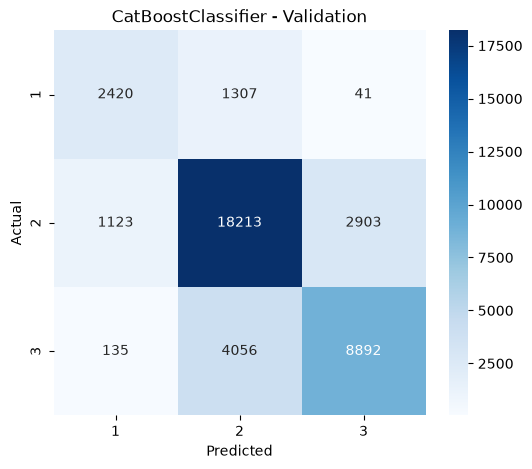

===== 테스트 성능 =====
Accuracy : 0.7568494026758077
Precision: 0.7310597391342387
Recall   : 0.7129302515056394
F1-score : 0.721095395917092


In [ ]:
# ===================================================
# 1. 라이브러리
# ===================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC

# ===================================================
# 2. 데이터 불러오기
# ===================================================
df_vars = pd.read_csv("nepal_building_damage_with_features.csv")

X = df_vars.drop(columns="damage_grade")
y = df_vars["damage_grade"] - 1  # 1,2,3 → 0,1,2


# ===================================================
# 3. 데이터 분할 (7 : 1.5 : 1.5)
# ===================================================
X_tr, X_temp, y_tr, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)


# ===================================================
# 4. 범주형 / 연속형 변수 구분
# ===================================================
geo_cols = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
cat_cols += [c for c in X.columns if c.startswith("has_")]
cat_cols += geo_cols

# 0/1로 생성한 파생변수도 범주형
cat_cols += [c for c in X.columns if c.endswith(("_grade2", "_grade3"))]

cat_cols = list(dict.fromkeys(cat_cols))
num_cols = [c for c in X.columns if c not in cat_cols]


# ===================================================
# 5. 인코딩 / 스케일링
# ===================================================
# SMOTENC 이전 전처리
preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), num_cols),
        (
            "cat",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            cat_cols,
        ),
    ]
)

# 범주형 컬럼 위치
cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))

# SMOTENC 이후 원핫인코딩
onehot = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), cat_idx)],
    remainder="passthrough",
    sparse_threshold=1.0,
)


# ===================================================
# 6. SMOTENC + CatBoostClassifier
# ===================================================
pipe = Pipeline(
    [
        ("preprocess", preprocessor),
        ("smote", SMOTENC(categorical_features=cat_idx, random_state=42)),
        ("onehot", onehot),
        ("model", CatBoostClassifier(random_state=42)),
    ]
)


# ===================================================
# 7. 모델 학습
# ===================================================
pipe.fit(X_tr, y_tr)


# ===================================================
# 8. 검증 데이터 평가
# ===================================================
y_pred = pipe.predict(X_val)

print("===== CatBoostClassifier 검증 성능 =====")
print("Accuracy :", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, average="macro", zero_division=0))
print("Recall   :", recall_score(y_val, y_pred, average="macro"))
print("F1-score :", f1_score(y_val, y_pred, average="macro"))

print("\n", classification_report(y_val, y_pred))


# ===================================================
# 9. 검증 혼동행렬
# ===================================================
cm = confusion_matrix(y_val, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", xticklabels=[1, 2, 3], yticklabels=[1, 2, 3]
)

plt.title("CatBoostClassifier - Validation")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# ===================================================
# 10. 테스트 데이터 최종 평가
# ===================================================
y_test_pred = pipe.predict(X_test)

print("===== 테스트 성능 =====")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print(
    "Precision:", precision_score(y_test, y_test_pred, average="macro", zero_division=0)
)
print("Recall   :", recall_score(y_test, y_test_pred, average="macro"))
print("F1-score :", f1_score(y_test, y_test_pred, average="macro"))